<a href="https://colab.research.google.com/github/adhishmodi/customer-churn-prediction/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction — Exploratory Data Analysis

Explore the IBM Telco Customer Churn dataset before model development. This notebook is designed to run in Google Colab and can also run from a local repository checkout.

## 1. Runtime and dataset setup

The repository is cloned into the Colab runtime when it is not already the current working directory. The raw dataset is intentionally not committed; upload the original CSV when prompted.

In [1]:
from pathlib import Path
import subprocess
import sys

REPOSITORY_URL = "https://github.com/adhishmodi/customer-churn-prediction.git"
EXPECTED_CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

current_dir = Path.cwd()
PROJECT_ROOT = next(
    (candidate for candidate in (current_dir, *current_dir.parents)
     if (candidate / "src").is_dir() and (candidate / "notebooks").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    colab_root = Path("/content")
    if not colab_root.exists():
        raise RuntimeError(
            "Run this notebook from the project root or its notebooks/ directory. "
            "In Google Colab, open it from the GitHub Colab link."
        )
    PROJECT_ROOT = colab_root / "customer-churn-prediction"
    if not (PROJECT_ROOT / "src").is_dir():
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORY_URL, str(PROJECT_ROOT)], check=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / EXPECTED_CSV
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Expected dataset: {DATA_PATH}")

Project root: /content/customer-churn-prediction
Expected dataset: /content/customer-churn-prediction/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f"Dataset not found at {DATA_PATH}. Download the Kaggle CSV and place it there."
        ) from exc

    print(f"Upload the original file named {EXPECTED_CSV}")
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if EXPECTED_CSV in uploaded:
        selected_name = EXPECTED_CSV
    elif len(csv_names) == 1:
        selected_name = csv_names[0]
    else:
        raise ValueError(f"Upload exactly one CSV, preferably named {EXPECTED_CSV}. Found: {csv_names}")
    if selected_name != EXPECTED_CSV:
        (DATA_PATH.parent / EXPECTED_CSV).write_bytes(uploaded[selected_name])
    else:
        DATA_PATH.write_bytes(uploaded[selected_name])

assert DATA_PATH.exists(), "Dataset setup did not create the expected CSV file."

Upload the original file named WA_Fn-UseC_-Telco-Customer-Churn.csv


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
raw_df = pd.read_csv(DATA_PATH)
print(f"Raw dataset shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())
raw_df.info()

Raw dataset shape: 7,043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Data quality checks

Keep the raw dataframe unchanged. Convert `TotalCharges` only in the analysis copy. Blank charges for zero-tenure customers represent customers with no billed tenure; other missing values remain missing for the later training pipeline to handle.

In [4]:
df = raw_df.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
zero_tenure_missing = df["TotalCharges"].isna() & df["tenure"].eq(0)
df.loc[zero_tenure_missing, "TotalCharges"] = 0.0

print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Duplicate rows:", int(df.duplicated().sum()))
print("TotalCharges blanks converted to zero for zero-tenure customers:", int(zero_tenure_missing.sum()))
print("Other TotalCharges values still missing:", int(df["TotalCharges"].isna().sum()))

Missing values by column:


,missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0
TotalCharges blanks converted to zero for zero-tenure customers: 11
Other TotalCharges values still missing: 0


## 3. Target distribution

Churn is the binary prediction target. Record the observed class counts and proportions rather than assuming a fixed class balance.

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


Observed churn rate: 26.54%


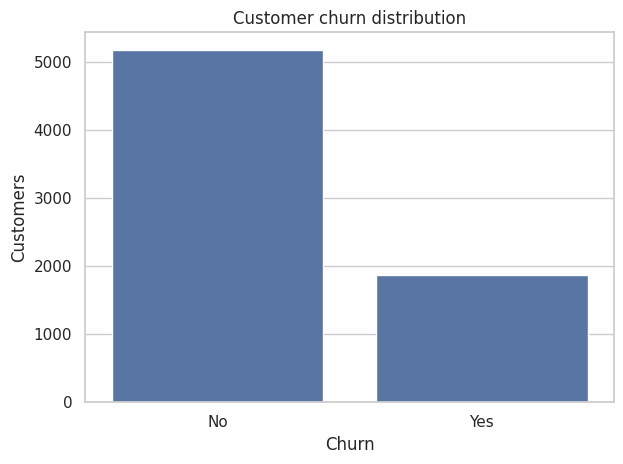

In [5]:
target_counts = df["Churn"].value_counts(dropna=False)
target_share = df["Churn"].value_counts(normalize=True, dropna=False).mul(100)
display(pd.DataFrame({"customers": target_counts, "percentage": target_share.round(2)}))
churn_rate = df["Churn"].eq("Yes").mean() * 100
print(f"Observed churn rate: {churn_rate:.2f}%")

ax = sns.countplot(data=df, x="Churn", order=["No", "Yes"])
ax.set(title="Customer churn distribution", xlabel="Churn", ylabel="Customers")
plt.tight_layout()
plt.show()

## 4. Numeric feature distributions

Compare tenure and billing distributions between customers who stayed and customers who churned.

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


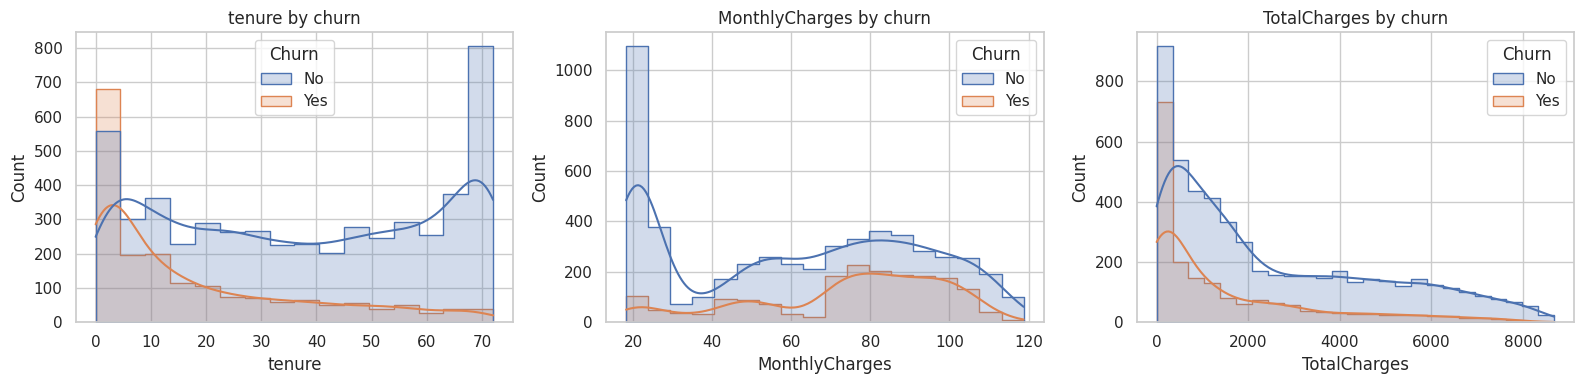

In [6]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[numeric_columns].describe().T)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for column, axis in zip(numeric_columns, axes):
    sns.histplot(data=df, x=column, hue="Churn", kde=True, element="step", ax=axis)
    axis.set_title(f"{column} by churn")
plt.tight_layout()
plt.show()

## 5. Churn rates across customer and service categories

Rates are calculated within each category. A high rate is an association in this dataset, not proof that the category causes churn.

,churn_rate_percent
gender,
Female,26.92
Male,26.16


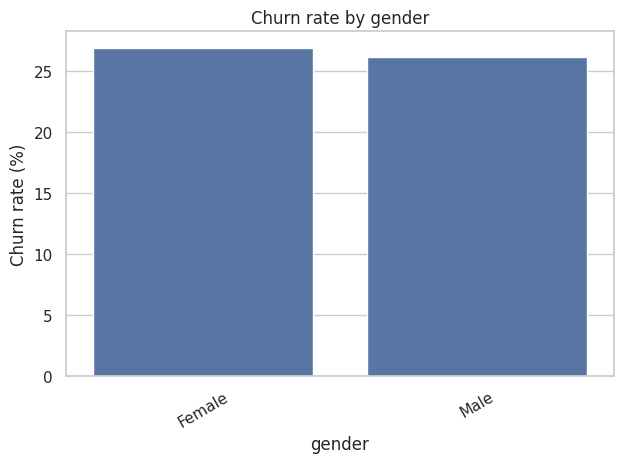

,churn_rate_percent
SeniorCitizen,
1,41.68
0,23.61


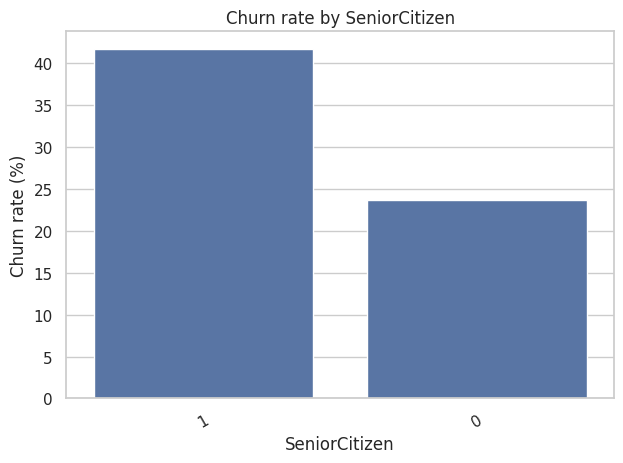

,churn_rate_percent
Partner,
No,32.96
Yes,19.66


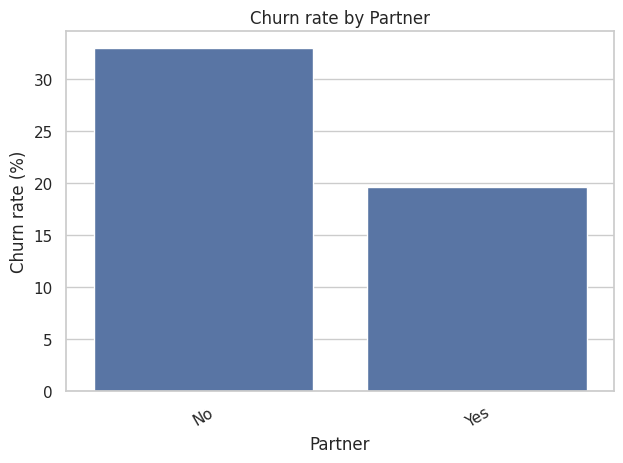

,churn_rate_percent
Dependents,
No,31.28
Yes,15.45


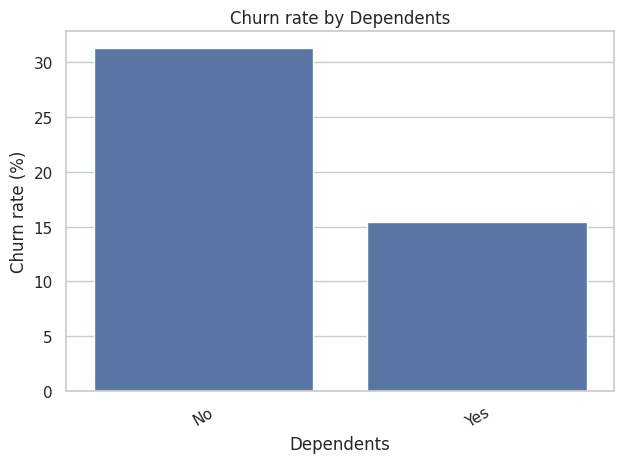

,churn_rate_percent
PhoneService,
Yes,26.71
No,24.93


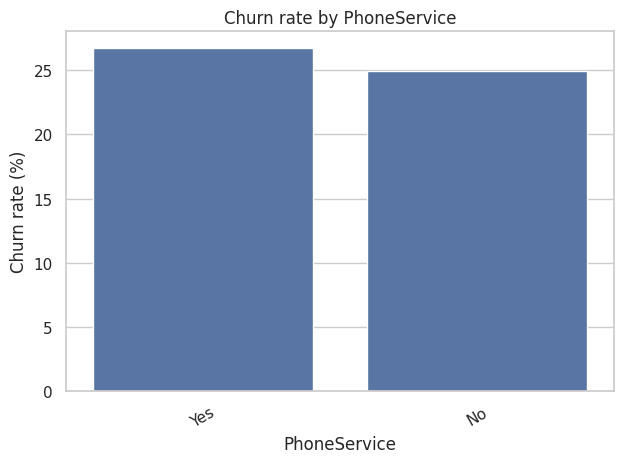

,churn_rate_percent
MultipleLines,
Yes,28.61
No,25.04
No phone service,24.93


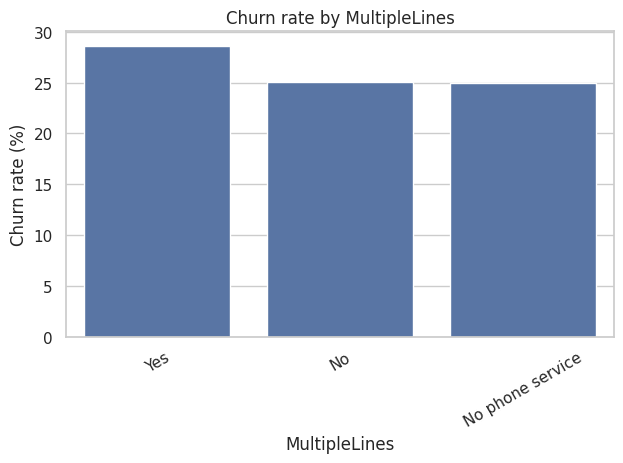

,churn_rate_percent
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


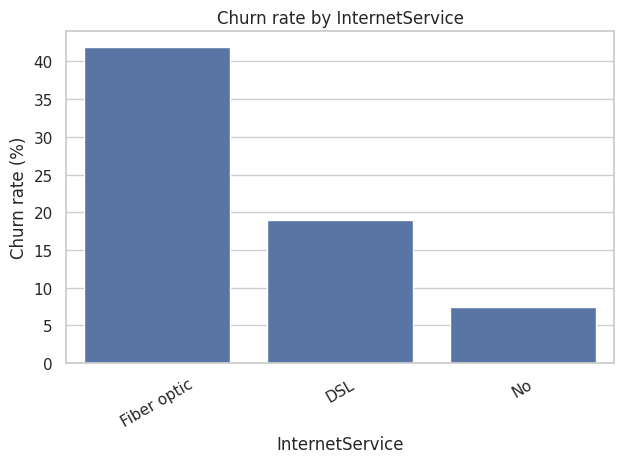

,churn_rate_percent
OnlineSecurity,
No,41.77
Yes,14.61
No internet service,7.40


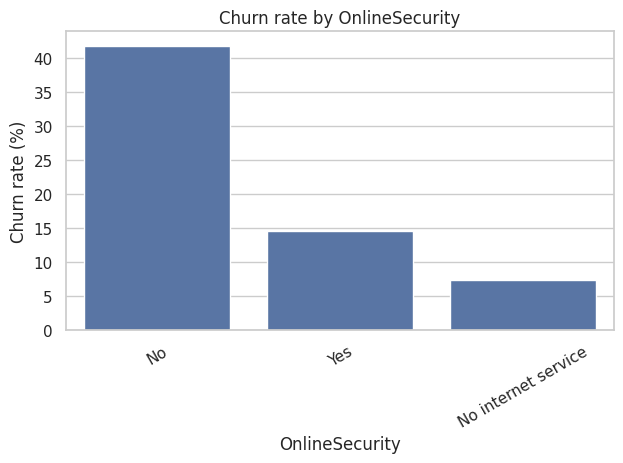

,churn_rate_percent
OnlineBackup,
No,39.93
Yes,21.53
No internet service,7.40


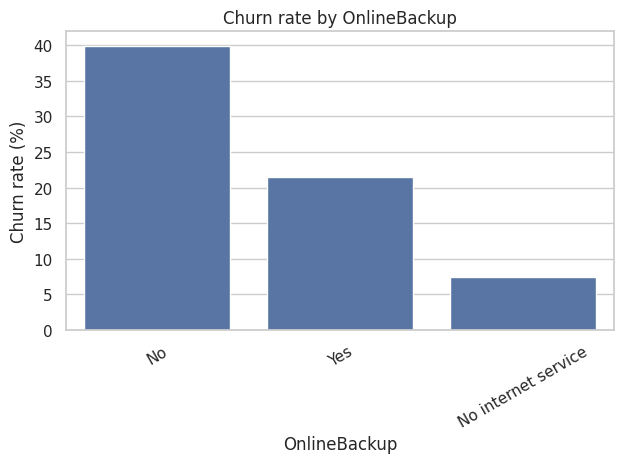

,churn_rate_percent
DeviceProtection,
No,39.13
Yes,22.50
No internet service,7.40


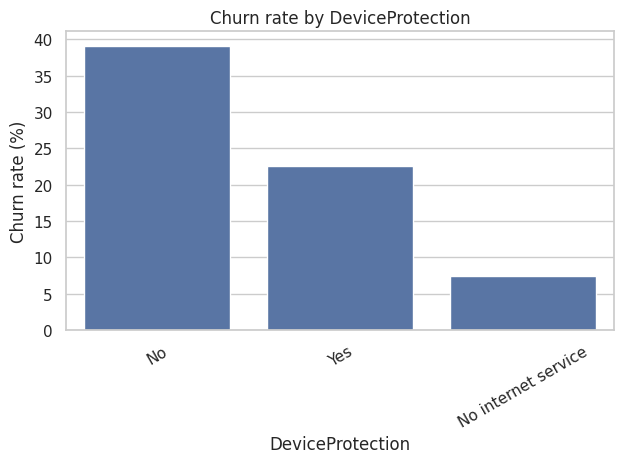

,churn_rate_percent
TechSupport,
No,41.64
Yes,15.17
No internet service,7.40


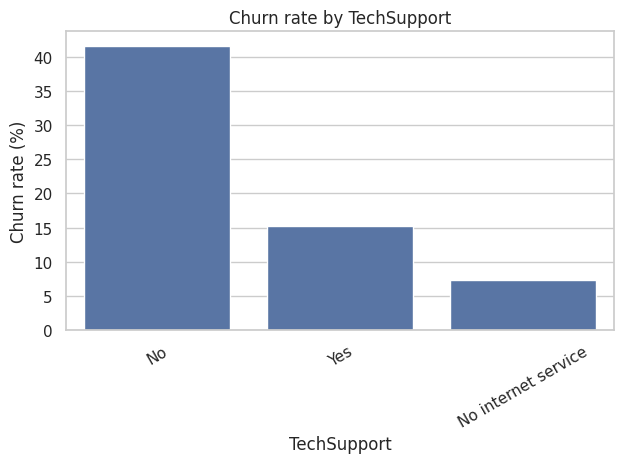

,churn_rate_percent
StreamingTV,
No,33.52
Yes,30.07
No internet service,7.40


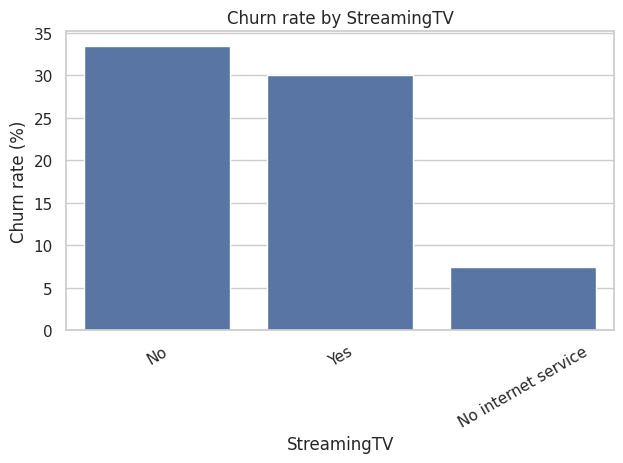

,churn_rate_percent
StreamingMovies,
No,33.68
Yes,29.94
No internet service,7.40


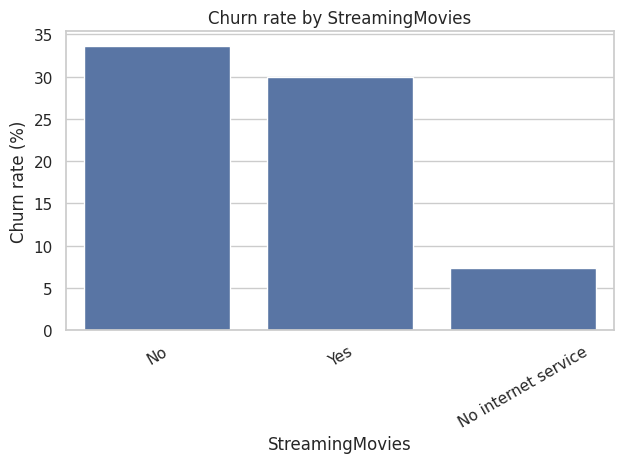

,churn_rate_percent
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


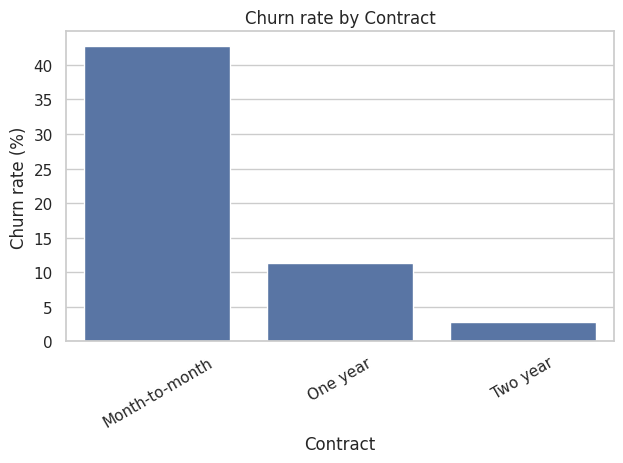

,churn_rate_percent
PaperlessBilling,
Yes,33.57
No,16.33


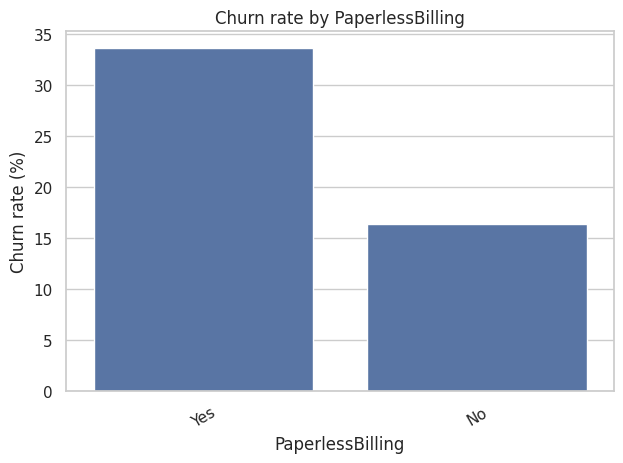

,churn_rate_percent
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


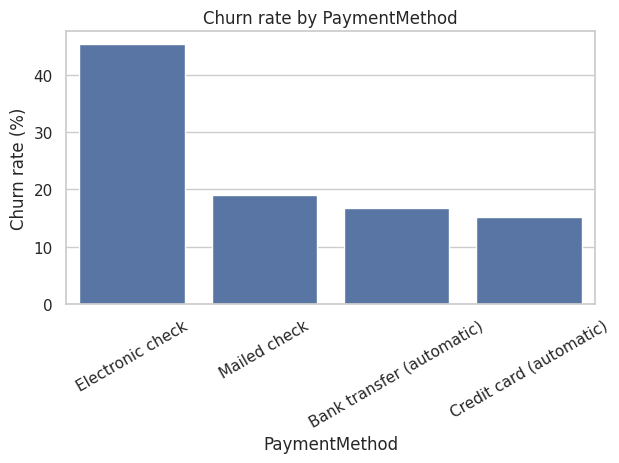

In [7]:
categorical_columns = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod"
]
churn_rate_tables = {}
for column in categorical_columns:
    rates = df.groupby(column, dropna=False)["Churn"].apply(lambda values: values.eq("Yes").mean()).sort_values(ascending=False)
    churn_rate_tables[column] = rates
    display((rates.mul(100).round(2)).rename("churn_rate_percent").to_frame())
    axis = sns.barplot(x=rates.index.astype(str), y=rates.values * 100)
    axis.set(title=f"Churn rate by {column}", xlabel=column, ylabel="Churn rate (%)")
    axis.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()

## 6. Numeric correlations

Correlation describes linear association among numeric variables. It is not a measure of causal influence.

,tenure,MonthlyCharges,TotalCharges,ChurnBinary
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.198
ChurnBinary,-0.352,0.193,-0.198,1.000


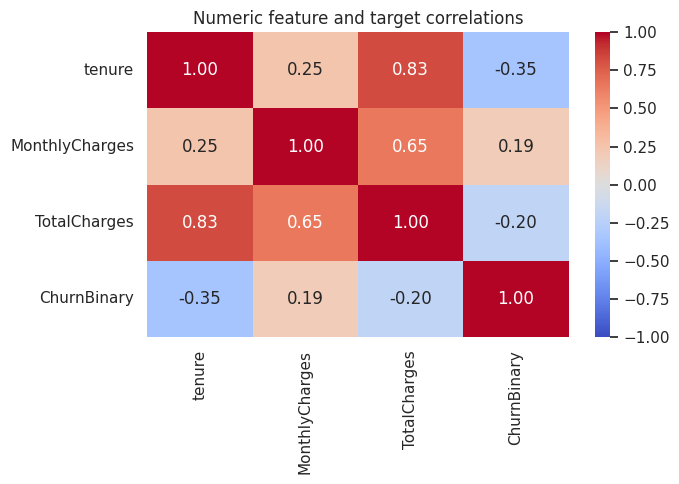

In [8]:
numeric_for_corr = df[numeric_columns].copy()
numeric_for_corr["ChurnBinary"] = df["Churn"].map({"No": 0, "Yes": 1})
correlation = numeric_for_corr.corr(numeric_only=True)
display(correlation.round(3))
plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Numeric feature and target correlations")
plt.tight_layout()
plt.show()

## 7. Initial findings and modeling considerations

The following cell prints observed category churn rates for selected features. Use the output to write conclusions after running the notebook; do not treat these associations as causal explanations.

In [9]:
for column in ["Contract", "PaymentMethod", "InternetService", "TechSupport", "OnlineSecurity"]:
    rates = churn_rate_tables[column].mul(100).round(2)
    print(f"{column}: highest observed category churn rate = {rates.index[0]} ({rates.iloc[0]:.2f}%)")

print("\nModeling notes:")
print("- Exclude customerID because it is an identifier.")
print("- Convert TotalCharges to numeric and handle remaining missing values inside the training pipeline.")
print("- Split the data before fitting imputers, encoders, or scalers.")
print("- Use cross-validation on the training split for model selection.")
print("- Reserve the held-out test split for final evaluation.")

Contract: highest observed category churn rate = Month-to-month (42.71%)
PaymentMethod: highest observed category churn rate = Electronic check (45.29%)
InternetService: highest observed category churn rate = Fiber optic (41.89%)
TechSupport: highest observed category churn rate = No (41.64%)
OnlineSecurity: highest observed category churn rate = No (41.77%)

Modeling notes:
- Exclude customerID because it is an identifier.
- Convert TotalCharges to numeric and handle remaining missing values inside the training pipeline.
- Split the data before fitting imputers, encoders, or scalers.
- Use cross-validation on the training split for model selection.
- Reserve the held-out test split for final evaluation.


## 8. Conclusion

After running all cells, summarize the strongest observed patterns here. Distinguish descriptive associations from model-based feature importance, and do not claim that any variable causes churn based only on this EDA.

In [10]:
print(f"Dataset rows: {len(df):,}")
print(f"Features excluding target and identifier: {df.shape[1] - 2}")
print(f"Observed churn rate: {churn_rate:.2f}%")
print(f"Duplicate rows: {int(df.duplicated().sum())}")
print("EDA complete. Record interpretation based on the displayed tables and charts.")

Dataset rows: 7,043
Features excluding target and identifier: 19
Observed churn rate: 26.54%
Duplicate rows: 0
EDA complete. Record interpretation based on the displayed tables and charts.
